In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import seaborn as sns
import os
import pandas as pd
import h5py
import sys
import colorsys
from matplotlib.colors import to_rgb
import matplotlib.ticker as ticker
import os


from pathlib import Path

# Import project modules
def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from train import barrier_from_sigma_samples
from utils import load_packed_hdf5, paper_three_point_barrier
from wong import sigma


plt.style.use(['science', 'notebook', 'ieee', 'grid'])
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,           # base font size for ticks and labels
    "axes.labelsize": 24,      # y-label size
    "axes.titlesize": 30,      # title
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 14,
    "mathtext.fontset": "cm",  # use Computer Modern math
    "axes.linewidth": 1.2,
})

/opt/software-current/2023.06/x86_64/intel/skylake_avx512/software/Python-bundle-PyPI/2023.06-GCCcore-12.3.0/lib/python3.11/site-packages/pyparsing/core.py:5596: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString


In [2]:
# -----------------------------
# USER EDITS: file lists
# -----------------------------
GP_CSVS = [
  "res_0.25MeV_noise0.01_gp_rbf.h5.csv",
  "res_0.50MeV_noise0.01_gp_rbf.h5.csv",
  "res_1.00MeV_noise0.01_gp_rbf.h5.csv",
  "res_2.00MeV_noise0.01_gp_rbf.h5.csv",
  "res_0.25MeV_noise0.02_gp_rbf.h5.csv",
  "res_0.50MeV_noise0.02_gp_rbf.h5.csv",
  "res_1.00MeV_noise0.02_gp_rbf.h5.csv",
  "res_2.00MeV_noise0.02_gp_rbf.h5.csv",
  "cv0.00_spacing0.5_gp_rbf.h5.csv",
  "cv0.25_spacing0.5_gp_rbf.h5.csv",
  "cv0.50_spacing0.5_gp_rbf.h5.csv",
  "cv0.75_spacing0.5_gp_rbf.h5.csv",
  "cv0.00_spacing1.0_gp_rbf.h5.csv",
  "cv0.25_spacing1.0_gp_rbf.h5.csv",
  "cv0.50_spacing1.0_gp_rbf.h5.csv",
  "cv0.75_spacing1.0_gp_rbf.h5.csv",
]

BNN_CSVS = [
  "res_0.25MeV_noise0.01_bnn_soc_d3lam1.h5.csv",
  "res_0.50MeV_noise0.01_bnn_soc_d3lam1.h5.csv",
  "res_1.00MeV_noise0.01_bnn_soc_d3lam1.h5.csv",
  "res_2.00MeV_noise0.01_bnn_soc_d3lam1.h5.csv",
  "res_0.25MeV_noise0.02_bnn_soc_d3lam1.h5.csv",
  "res_0.50MeV_noise0.02_bnn_soc_d3lam1.h5.csv",
  "res_1.00MeV_noise0.02_bnn_soc_d3lam1.h5.csv",
  "res_2.00MeV_noise0.02_bnn_soc_d3lam1.h5.csv",
  "cv0.00_spacing0.5_bnn_soc_d3lam1.h5.csv",
  "cv0.25_spacing0.5_bnn_soc_d3lam1.h5.csv",
  "cv0.50_spacing0.5_bnn_soc_d3lam1.h5.csv",
  "cv0.75_spacing0.5_bnn_soc_d3lam1.h5.csv",
  "cv0.00_spacing1.0_bnn_soc_d3lam1.h5.csv",
  "cv0.25_spacing1.0_bnn_soc_d3lam1.h5.csv",
  "cv0.50_spacing1.0_bnn_soc_d3lam1.h5.csv",
  "cv0.75_spacing1.0_bnn_soc_d3lam1.h5.csv",
]

TITLES = [
    r"$\kappa=0.00$, $\Delta E=0.25$ MeV, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=0.50$ MeV, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=1.00$ MeV, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=2.00$ MeV, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=0.25$ MeV, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=0.50$ MeV, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=1.00$ MeV, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=2.00$ MeV, $\eta=0.02$",
    r"$\kappa=0.00$, $\Delta E=0.5$ MeV, $\eta=0.01$",
    r"$\kappa=0.25$, $\Delta E=0.5$ MeV, $\eta=0.01$",
    r"$\kappa=0.50$, $\Delta E=0.5$ MeV, $\eta=0.01$",
    r"$\kappa=0.75$, $\Delta E=0.5$ MeV, $\eta=0.01$",
    r"$\kappa=0.00$, $\Delta E=1.0$ MeV, $\eta=0.01$",
    r"$\kappa=0.25$, $\Delta E=1.0$ MeV, $\eta=0.01$",
    r"$\kappa=0.50$, $\Delta E=1.0$ MeV, $\eta=0.01$",
    r"$\kappa=0.75$, $\Delta E=1.0$ MeV, $\eta=0.01$",
]

# base directories for the d3-lambda-1 rerun
GP_DIR  = str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "gps")
BNN_DIR = str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "bnns_with_df")


In [3]:
"""
# Add metrics from the pointwise median predictive barrier to each summary CSV.
# Existing mean-based columns are preserved; completed files are skipped on reruns.
from utils import peak_metrics_anchored

# This code recomputes metrics using medians instead of means. 

MEDIAN_METRIC_COLUMNS = [
    "barrier_MAE_median",
    "barrier_RMSE_median",
    "barrier_peak_loc_pred_median",
    "barrier_peak_ht_pred_median",
    "barrier_fwhm_pred_median",
    "barrier_peak_loc_resid_median",
    "barrier_peak_ht_resid_median",
    "barrier_fwhm_resid_median",
]


def add_median_barrier_metrics(h5_path, csv_path, is_bnn=False,
                               peak_window=6.0, barrier_smooth=5):
    df = pd.read_csv(csv_path)
    if all(col in df.columns for col in MEDIAN_METRIC_COLUMNS):
        print(f"Median metrics already present: {csv_path}")
        return

    results = {col: [] for col in MEDIAN_METRIC_COLUMNS}

    with h5py.File(h5_path, "r") as f:
        for _, row in df.iterrows():
            group_name = str(int(row["index"]))
            if group_name not in f:
                for col in MEDIAN_METRIC_COLUMNS:
                    results[col].append(np.nan)
                continue

            grp = f[group_name]
            x_pred = np.asarray(grp["x_pred"][:], dtype=float)
            mask = (x_pred >= float(row["x_min"])) & (x_pred <= float(row["x_max"]))
            x = x_pred[mask]

            if is_bnn and "d2_samples" in grp:
                D_samples = np.asarray(grp["d2_samples"][:, mask], dtype=float)
            else:
                sigma_samples = np.asarray(grp["y_samples"][:, mask], dtype=float)
                D_samples = barrier_from_sigma_samples(x, sigma_samples)

            D_median = np.nanmedian(D_samples, axis=0)
            sigma_true = sigma(
                x,
                E0=float(row["E0_true"]),
                R0=float(row["R0_true"]),
                hbarw=float(row["hw_true"]),
            )
            D_true = barrier_from_sigma_samples(x, sigma_true[None, :])[0]

            error = D_median - D_true
            pred_loc, pred_ht, pred_fwhm = peak_metrics_anchored(
                x, D_median, float(row["E0_true"]),
                window=peak_window, smooth=barrier_smooth,
            )

            results["barrier_MAE_median"].append(float(np.nanmean(np.abs(error))))
            results["barrier_RMSE_median"].append(float(np.sqrt(np.nanmean(error**2))))
            results["barrier_peak_loc_pred_median"].append(pred_loc)
            results["barrier_peak_ht_pred_median"].append(pred_ht)
            results["barrier_fwhm_pred_median"].append(pred_fwhm)
            results["barrier_peak_loc_resid_median"].append(pred_loc - row["barrier_peak_loc_true"])
            results["barrier_peak_ht_resid_median"].append(pred_ht - row["barrier_peak_ht_true"])
            results["barrier_fwhm_resid_median"].append(pred_fwhm - row["barrier_fwhm_true"])

    for col, values in results.items():
        df[col] = values
    df.to_csv(csv_path, index=False)
    print(f"Wrote median metrics: {csv_path}")


for filename in GP_CSVS:
    add_median_barrier_metrics(
        os.path.join(GP_DIR, filename[:-4]),
        os.path.join(GP_DIR, filename),
        is_bnn=False,
    )

for filename in BNN_CSVS:
    add_median_barrier_metrics(
        os.path.join(BNN_DIR, filename[:-4]),
        os.path.join(BNN_DIR, filename),
        is_bnn=True,
    )

"""

'\n# Add metrics from the pointwise median predictive barrier to each summary CSV.\n# Existing mean-based columns are preserved; completed files are skipped on reruns.\nfrom utils import peak_metrics_anchored\n\n# This code recomputes metrics using medians instead of means. \n\nMEDIAN_METRIC_COLUMNS = [\n    "barrier_MAE_median",\n    "barrier_RMSE_median",\n    "barrier_peak_loc_pred_median",\n    "barrier_peak_ht_pred_median",\n    "barrier_fwhm_pred_median",\n    "barrier_peak_loc_resid_median",\n    "barrier_peak_ht_resid_median",\n    "barrier_fwhm_resid_median",\n]\n\n\ndef add_median_barrier_metrics(h5_path, csv_path, is_bnn=False,\n                               peak_window=6.0, barrier_smooth=5):\n    df = pd.read_csv(csv_path)\n    if all(col in df.columns for col in MEDIAN_METRIC_COLUMNS):\n        print(f"Median metrics already present: {csv_path}")\n        return\n\n    results = {col: [] for col in MEDIAN_METRIC_COLUMNS}\n\n    with h5py.File(h5_path, "r") as f:\n       

In [4]:
# plot settings
CUTOFF = 20000
WHICH  = "barrier"   # "barrier" or "sigma"
ALPHA  = 0.75
LW     = 1.6


KIND = "barrier"          # "barrier" or "sigma"
NORMALIZE = True          # normalized by hw_true * R0_true^2 (like your script)
CUTOFF_RMSE = 200000
HT_GATE = 1000.0           # |ht_true - ht_pred| < 100
GP_STRIDE = 10            # GP index = BNN index * 10

# colors (consistent with your earlier aesthetic)
GP_COLOR  = "tab:blue"
BNN_COLOR = "tab:green"



In [5]:

# --- CONFIGURATION ---
GP_DIR = str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "gps")
BNN_DIR = str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "bnns_with_df")
SAVE_DIR = "../plots"

SETTINGS = {
    "cutoff_rmse": 20000,
    "ht_gate": 1000.0,
    "gp_stride": 10,
    "normalize": True,
    "kind": "barrier" 
}

# --- CORE UTILITIES ---

def get_shades(base_color, n, lightness=(0.3, 0.75)):
    r, g, b = to_rgb(base_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    ls = np.linspace(lightness[0], lightness[1], n)
    return [colorsys.hls_to_rgb(h, float(l_val), s) for l_val in ls]

def load_processed_df(filename, base_dir, is_bnn=False, center="mean"):
    path = os.path.join(base_dir, filename)
    if not os.path.exists(path):
        print(f"File not found: {path}")
        return pd.DataFrame()
    
    df = pd.read_csv(path)
    
    # 1. Numeric conversion
    cols_to_fix = [c for c in df.columns if any(x in c for x in ['MAE', 'resid', 'true', 'pred', 'RMSE', 'cov', 'index'])]
    for col in cols_to_fix:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    suffix = "" if center == "mean" else "_median"

    # 2. Universal RMSE Filter
    rmse_col = f"barrier_RMSE{suffix}"
    if rmse_col in df.columns:
        df = df[df[rmse_col] <= SETTINGS["cutoff_rmse"]]

    # 3. BNN Convergence Gate
    pred_ht_col = f"barrier_peak_ht_pred{suffix}"
    if is_bnn and "barrier_peak_ht_true" in df.columns and pred_ht_col in df.columns:
        gate = (df["barrier_peak_ht_true"] - df[pred_ht_col]).abs() < SETTINGS["ht_gate"]
        df = df[gate]
    
    # 4. Normalization
    if SETTINGS["normalize"] and "hw_true" in df.columns:
        norm = (df["R0_true"] ** 2) / df["hw_true"] 
        norm = norm.replace(0, np.nan)
        for target in ["barrier_MAE", "barrier_RMSE", "barrier_MAE_median", "barrier_RMSE_median"]:
            if target in df.columns:
                df[target] = df[target] / norm
                
    return df.dropna(subset=['index'])

# --- PLOTTING FUNCTIONS ---

def plot_coverage_curves(gp_files, bnn_files):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 100], [0, 100], 'k--', alpha=1.0, label="Ideal")
    
    colors_gp = get_shades("tab:blue", len(gp_files))
    colors_bnn = get_shades("tab:green", len(bnn_files))

    for files, colors, label_prefix, marker in [
        (gp_files, colors_gp, "GP", "o"),
        (bnn_files, colors_bnn, "AutoBNN", "x"),
    ]:
        for i, (fname, col) in enumerate(zip(files, colors)):
            base_dir = BNN_DIR if "bnn" in fname else GP_DIR
            df = load_processed_df(fname, base_dir=base_dir, is_bnn=("bnn" in fname))
            if df.empty: continue
            
            prefix = f"{SETTINGS['kind']}_emp_cov_"
            cov_cols = [c for c in df.columns if c.startswith(prefix)]
            
            # Extract numerical level from column name and sort numerically
            col_map = {c: int(c.split('_')[-1]) for c in cov_cols}
            sorted_cols = sorted(
                [c for c in cov_cols if col_map[c] < 100],
                key=lambda x: col_map[x],
            )
            
            levels = [col_map[c] for c in sorted_cols]
            means = [df[c].mean() * 100 for c in sorted_cols] # Convert to %
            
            ax.plot(levels, means, color=col, alpha=0.6, marker=marker,
                    label=label_prefix if i == 0 else None)

    ax.set(xlabel="Nominal Credibility (%)", ylabel="Average Coverage (%)") # ({SETTINGS['kind'].capitalize()})
    ax.set_title(rf"$D_f$ Empirical Coverage", pad=15)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.legend(frameon=False, fontsize=18)
    plt.savefig(f"{SAVE_DIR}/Coverage.png", dpi=300)

# Ensure you have the environment ready: 
# conda install matplotlib=3.7.1
# pip install scienceplots==2.1.0

def plot_violin_grid(gp_files, bnn_files, titles, metric_type="MAE", center="mean"):
    # --- 1. PRE-CALCULATE DATA AND GLOBAL Y-LIMITS ---
    processed_pairs = []
    all_raw_vals = []
    metric_suffix = "" if center == "mean" else "_median"
    target_err = f"{SETTINGS['kind']}_{metric_type}{metric_suffix}"

    for gp_f, bnn_f in zip(gp_files, bnn_files):
        df_gp = load_processed_df(gp_f, base_dir=GP_DIR, is_bnn=False, center=center)
        df_bnn = load_processed_df(bnn_f, base_dir=BNN_DIR, is_bnn=True, center=center)
        
        if not df_gp.empty and not df_bnn.empty:
            # Align indices
            df_bnn['match_idx'] = (df_bnn['index'] * SETTINGS['gp_stride']).astype(int)
            df_gp['index_int'] = df_gp['index'].astype(int)
            matched = pd.merge(df_bnn, df_gp, left_on='match_idx', right_on='index_int', suffixes=('_bnn', '_gp'))
            
            if not matched.empty:
                v_gp = matched[f"{target_err}_gp"].astype(float)
                v_bnn = matched[f"{target_err}_bnn"].astype(float)
                
                # Filter for strictly positive values for log scale
                valid_vals = np.concatenate([v_gp[v_gp > 0], v_bnn[v_bnn > 0]])
                all_raw_vals.extend(valid_vals.tolist())
                processed_pairs.append((matched, df_gp, df_bnn))
            else:
                processed_pairs.append(None)
        else:
            processed_pairs.append(None)

    # Calculate global limits in raw space (using multiplicative buffers for log scale)
    if all_raw_vals:
        y_min, y_max = min(all_raw_vals), max(all_raw_vals)
        global_ylim = (y_min * 0.5, y_max * 1.2) 
    else:
        global_ylim = (1e-4, 1e1)

    # --- 2. PLOTTING WITH SCIENCEPLOTS ---
    # Using 'no-latex' to avoid font errors if TeX is not installed
    fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharey=True, layout="constrained")
    axes_flat = axes.flatten()

    for i, pair_data in enumerate(processed_pairs):
        ax = axes_flat[i]
        if pair_data is None:
            ax.text(0.5, 0.5, "Insufficient Data", ha='center', transform=ax.transAxes)
            ax.set_axis_off()
            continue
            
        matched, df_gp_raw, df_bnn_raw = pair_data

        gp_v = matched[f"{target_err}_gp"].astype(float)
        bnn_v = matched[f"{target_err}_bnn"].astype(float)
        
        # Construct plot DataFrame (Raw Values)
        plot_df = pd.DataFrame({
            "val": np.concatenate([gp_v, bnn_v]),
            "model": ["GP"]*len(gp_v) + ["AutoBNN"]*len(bnn_v),
            "x": [0] * (len(gp_v) + len(bnn_v))
        })

        # sns.violinplot handles the log KDE and log axis simultaneously
        sns.violinplot(data=plot_df, x="x", y="val", hue="model", split=True,
                        log_scale=True, 
                        cut=1,
                        hue_order=["GP", "AutoBNN"],
                        palette={"GP": "tab:blue", "AutoBNN": "tab:green"}, 
                        ax=ax, inner="quartile", density_norm="area", common_norm=True)

        # --- 3. PERCENT ERROR ANNOTATIONS ---
        for name, m_df, color, side in [('GP', df_gp_raw, 'tab:blue', 0.05), ('BNN', df_bnn_raw, 'tab:green', 0.95)]:
            def get_mape(suffix):
                base_resid = "barrier_fwhm_resid" if suffix == "fwhm" else f"barrier_peak_{suffix}_resid"
                col_resid = base_resid if center == "mean" else f"{base_resid}_median"
                col_true = f"barrier_fwhm_true" if suffix == "fwhm" else f"barrier_peak_{suffix}_true"
                
                if col_resid in m_df.columns and col_true in m_df.columns:
                    resid = m_df[col_resid].abs()
                    true_val = m_df[col_true].abs()
                    mask = (true_val > 1e-9)
                    return (resid[mask] / true_val[mask]).mean() * 100
                return np.nan

            p_loc, p_ht, p_fw = get_mape("loc"), get_mape("ht"), get_mape("fwhm")
            txt = f"L: {p_loc:.1f}%\nH: {p_ht:.1f}%\nW: {p_fw:.1f}%"
            
            ax.text(side, 0.05, txt, transform=ax.transAxes, color='black', fontsize=11,
                    ha=('left' if side < 0.5 else 'right'), 
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor=color, boxstyle="round,pad=0.2"))

        ax.set_title(titles[i], fontsize=13)
        ax.set_ylim(global_ylim)
        ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, subs=(1.0,)))
        ax.set(xlabel="", ylabel="", xticks=[])
        if ax.get_legend(): ax.get_legend().remove()
    
    # Cleaner label without the "log" prefix since the axis scale reflects the log mapping
    ylabel_str = r"$(\frac{\hbar \omega_0 }{R_0 ^2}) \|\delta D_f\|_1$ (mb/MeV)" if metric_type == "MAE" else r"$\|\delta D_f\|_2 / \hbar \omega R_0 ^2$"
    fig.supylabel(ylabel_str, fontsize=28,)
    plt.savefig(f"{SAVE_DIR}/{metric_type}_Grid{metric_suffix}.png", dpi=300)

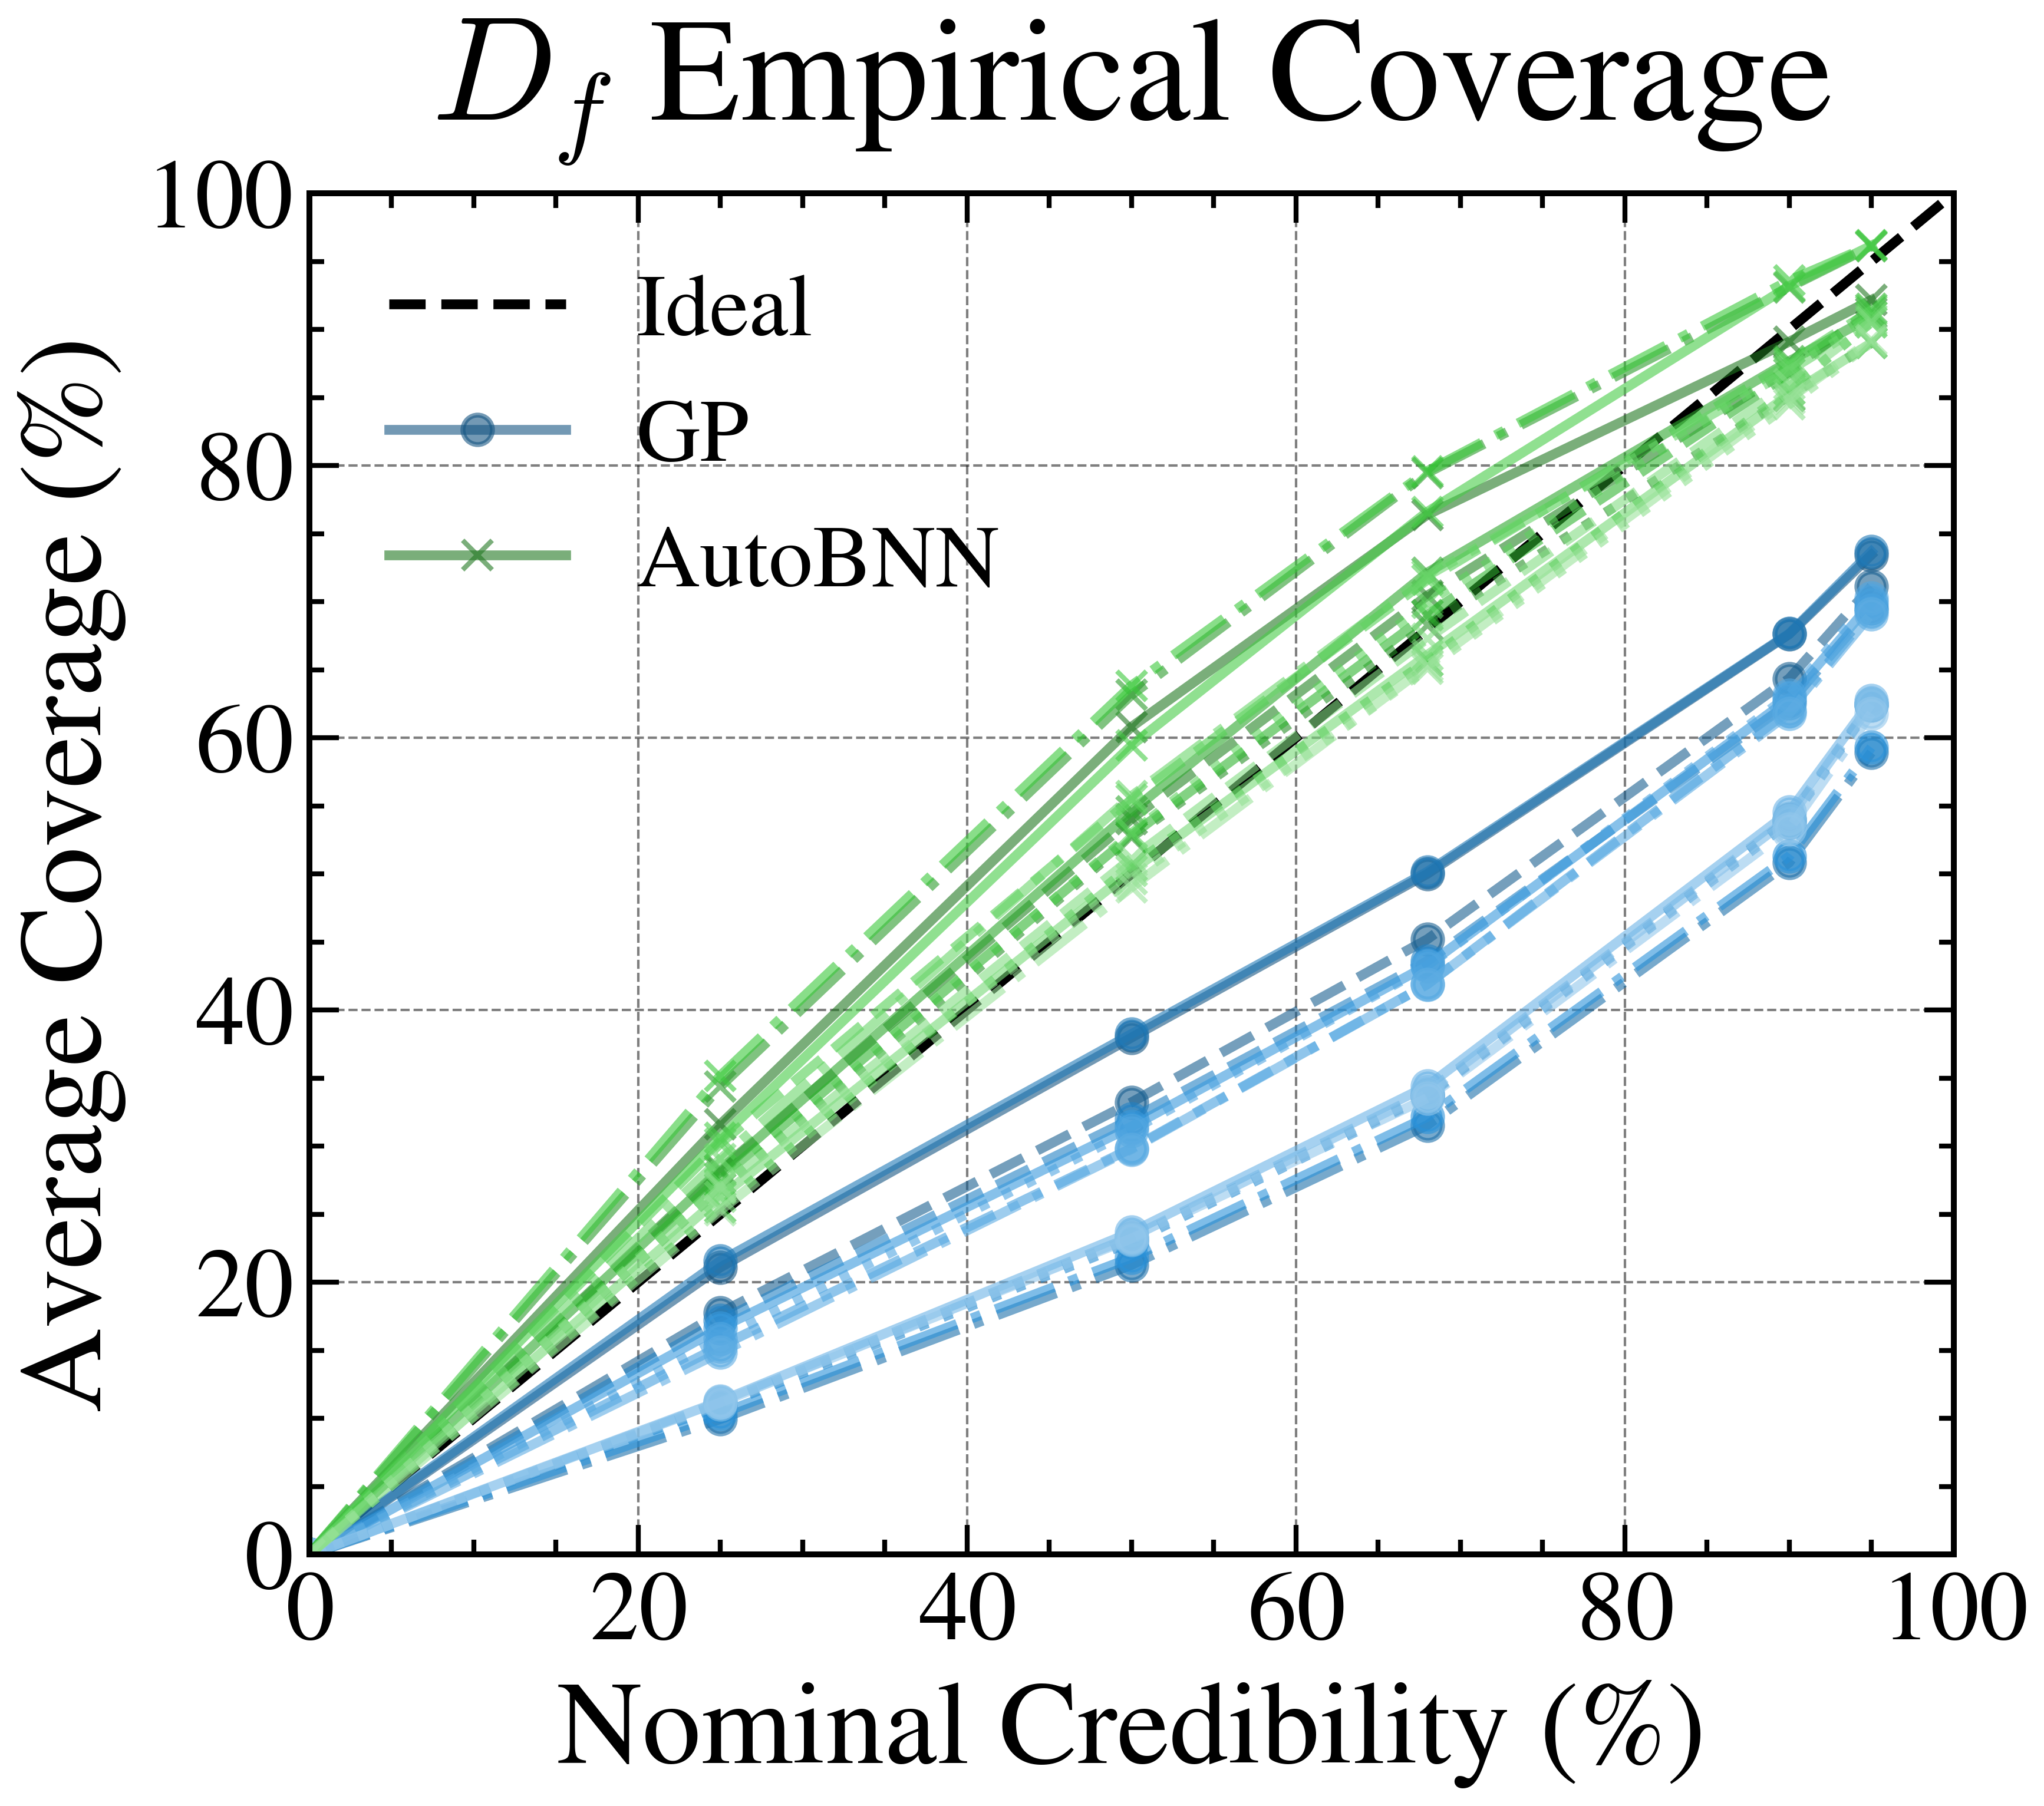

In [6]:
plot_coverage_curves(GP_CSVS, BNN_CSVS)

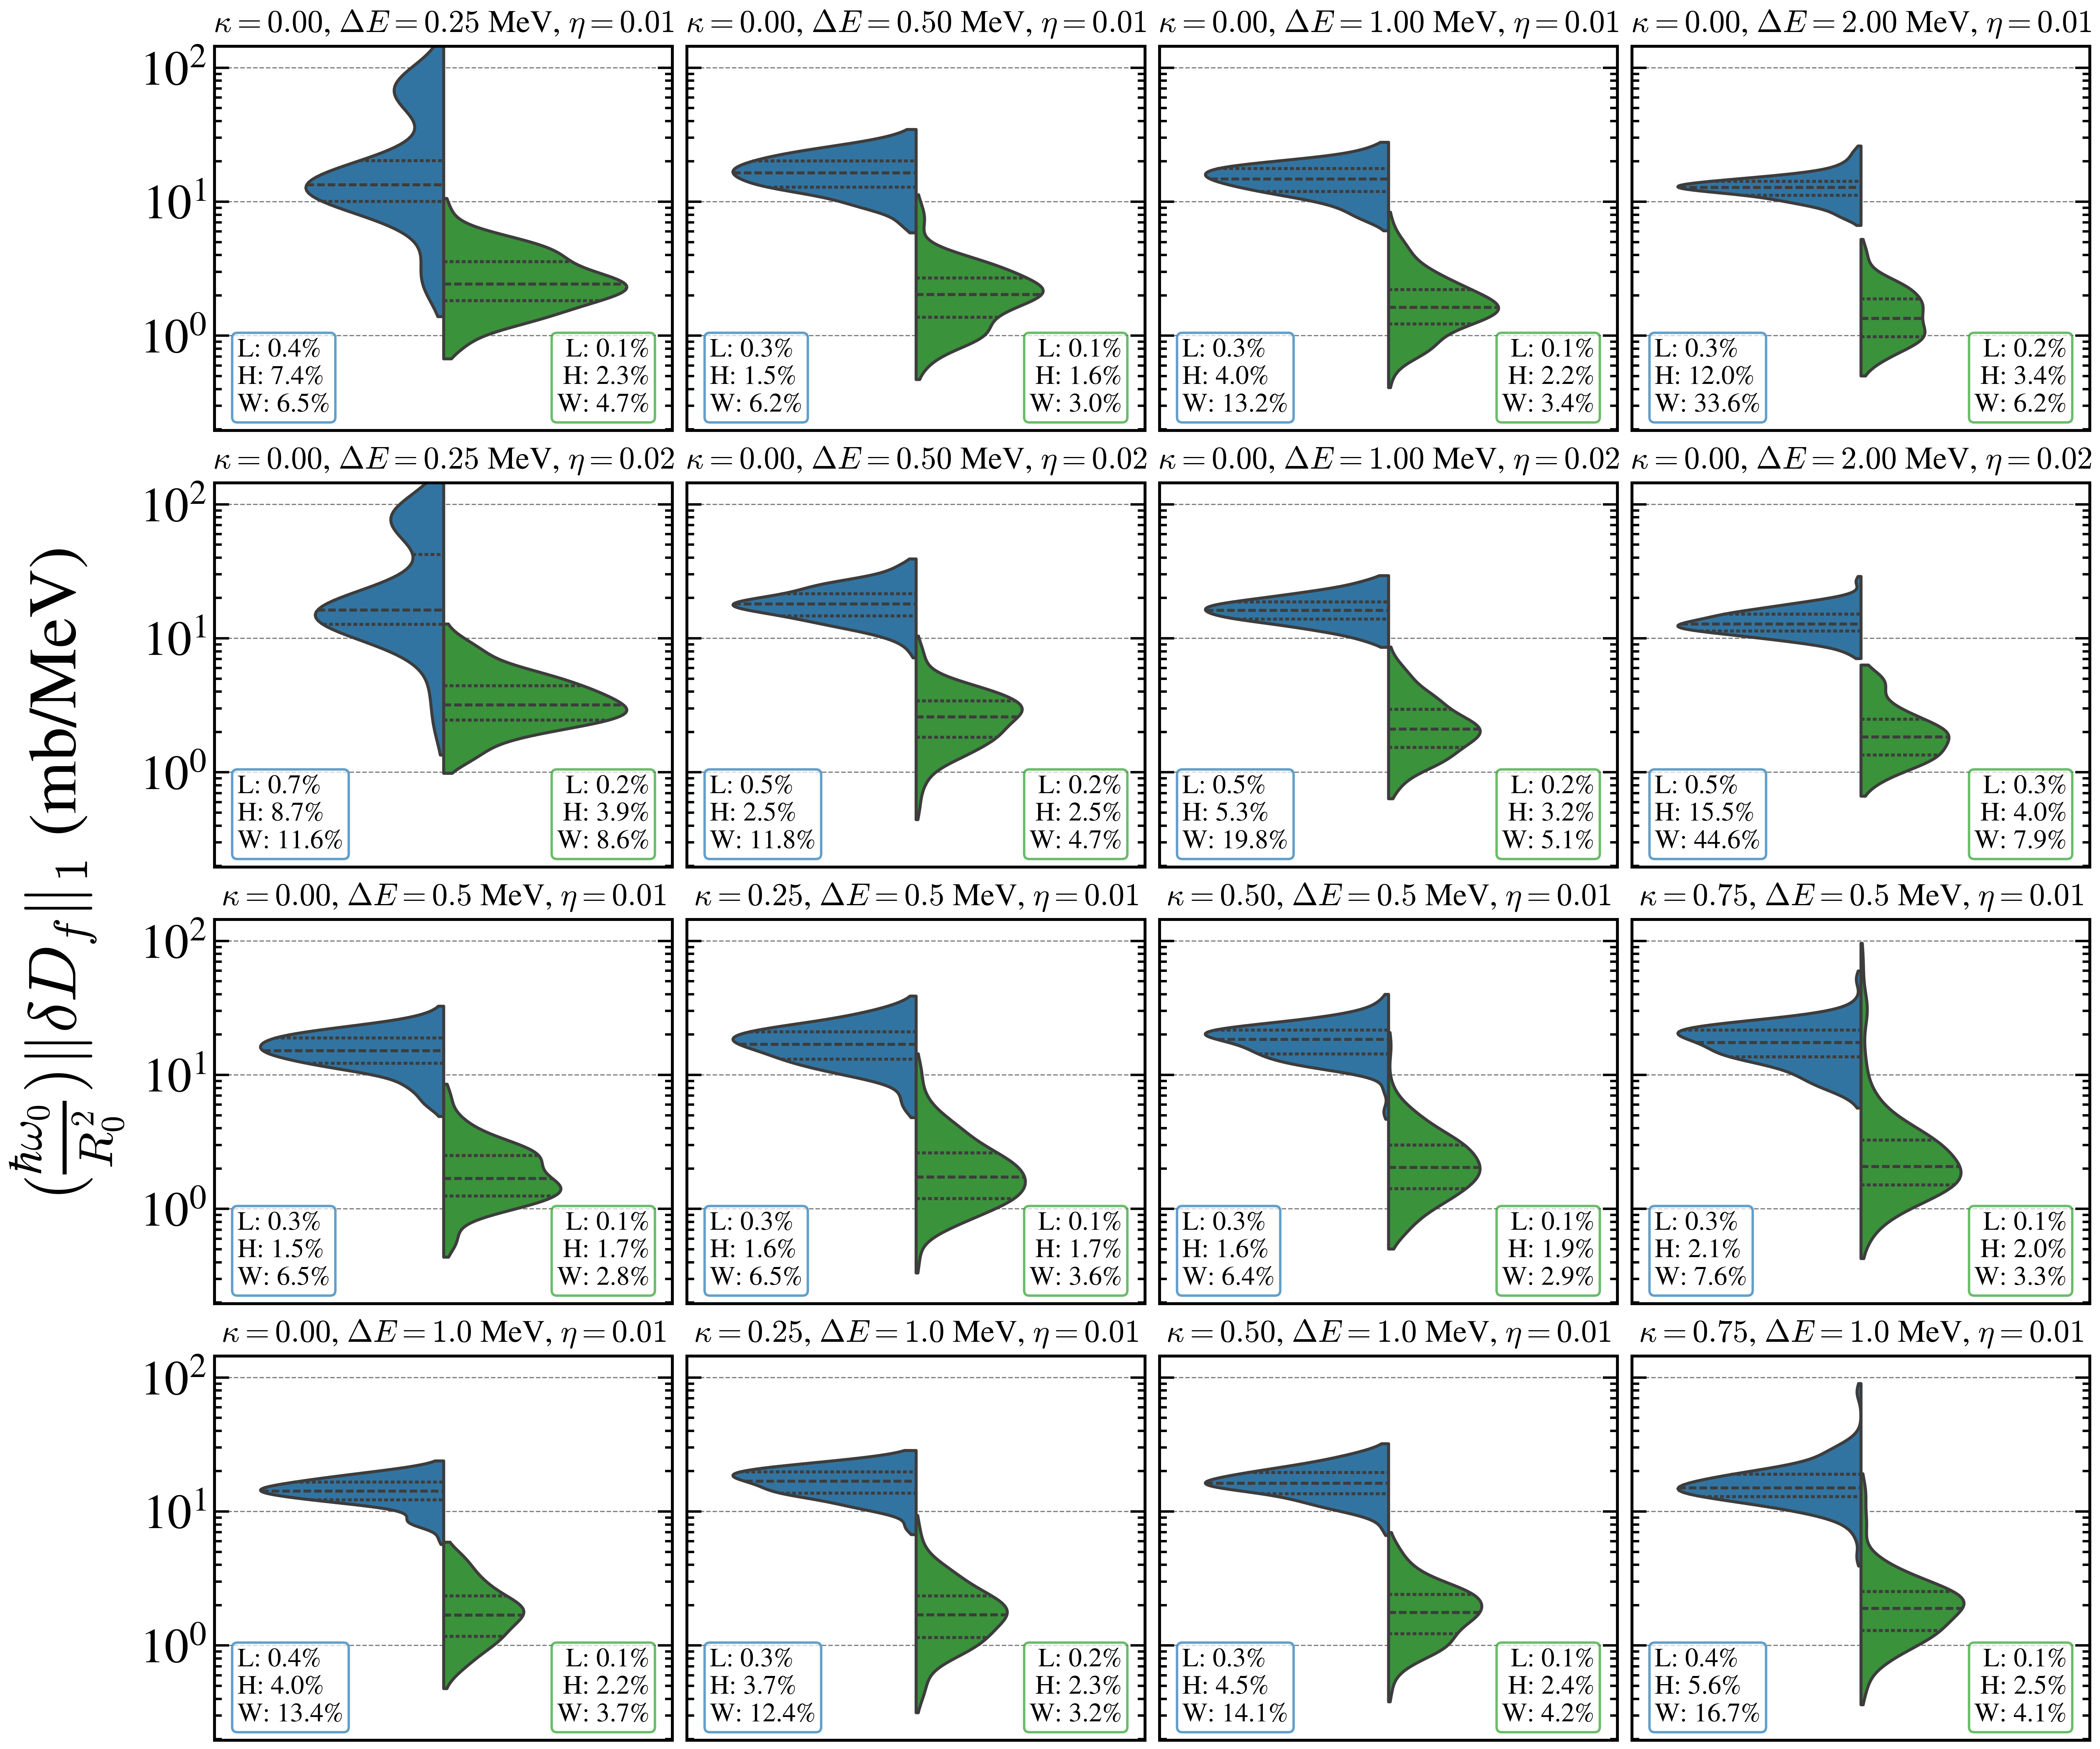

In [7]:
plot_violin_grid(GP_CSVS, BNN_CSVS, TITLES, metric_type="MAE", center="median")
plt.show()

### Experimental Plots

In [8]:
def percentile_bands(samples, levels=(0.68, 0.95)):
    out = {}
    for lev in levels:
        lo = 100 * (0.5 - lev / 2.0)
        hi = 100 * (0.5 + lev / 2.0)
        out[f"lower_{int(round(100*lev))}"] = np.percentile(samples, lo, axis=0)
        out[f"upper_{int(round(100*lev))}"] = np.percentile(samples, hi, axis=0)
    return out


def crps_from_samples(y_true, y_samps):
    """
    Empirical-sample CRPS at each point.

    y_true  : (N,)
    y_samps : (S, N)
    returns : (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    term1 = np.mean(np.abs(y_samps - y_true[None, :]), axis=0)
    pairwise = np.abs(y_samps[:, None, :] - y_samps[None, :, :])
    term2 = 0.5 * np.mean(pairwise, axis=(0, 1))
    return term1 - term2


def kl_gaussian_exp_vs_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Per-point KL divergence D_KL(P_exp || Q_pred), where

      P_exp  = N(y_true, y_err^2)
      Q_pred ≈ N(mean(samples), std(samples)^2)

    y_true : (N,)
    y_err  : (N,)
    y_samps: (S, N)

    returns: (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu_q = np.mean(y_samps, axis=0)
    std_q = np.std(y_samps, axis=0, ddof=1)

    std_p = np.maximum(y_err, eps)
    std_q = np.maximum(std_q, eps)

    kl = np.log(std_q / std_p) + (
        std_p**2 + (y_true - mu_q)**2
    ) / (2.0 * std_q**2) - 0.5

    return kl


def reduced_chi2(y_true, y_pred_mean, y_err, dof_correction=0, eps=1e-12):
    y_err = np.maximum(np.asarray(y_err, dtype=float), eps)
    resid = (np.asarray(y_true) - np.asarray(y_pred_mean)) / y_err
    nu = max(len(y_true) - dof_correction, 1)
    return np.sum(resid**2) / nu


def nlpd_gaussian_from_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Pointwise NLPD using Gaussian approximation to predictive samples and
    adding experimental variance in quadrature:

      y_obs ~ N(mu_pred, std_pred^2 + y_err^2)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu = np.mean(y_samps, axis=0)
    std_pred = np.std(y_samps, axis=0, ddof=1)
    var_tot = np.maximum(std_pred**2 + y_err**2, eps)

    nlpd = 0.5 * np.log(2.0 * np.pi * var_tot) + 0.5 * (y_true - mu)**2 / var_tot
    return nlpd


def coverage95_error_from_samples(y_true, y_samps):
    """
    Returns per-point 0/1 coverage indicator converted later to a score.
    """
    lo = np.percentile(y_samps, 2.5, axis=0)
    hi = np.percentile(y_samps, 97.5, axis=0)
    covered = ((y_true >= lo) & (y_true <= hi)).astype(float)
    return covered


def make_energy_weights(E):
    """
    Quadrature-like normalized weights on experimental energies.
    """
    E = np.asarray(E, dtype=float)
    N = len(E)
    if N == 1:
        return np.array([1.0])

    w = np.zeros(N, dtype=float)
    w[0] = 0.5 * (E[1] - E[0])
    w[-1] = 0.5 * (E[-1] - E[-2])
    for i in range(1, N - 1):
        w[i] = 0.5 * (E[i + 1] - E[i - 1])

    w = np.maximum(w, 0.0)
    s = np.sum(w)
    if s <= 0:
        return np.ones(N) / N
    return w / s


def safe_log_transform(y, y_err=None, y_samps=None, eps=1e-12):
    """
    log transform for positive sigma-like quantities.
    y_err is propagated with sigma_log ~ sigma_y / y.
    """
    y = np.asarray(y, dtype=float)
    y_clip = np.maximum(y, eps)
    logy = np.log(y_clip)

    out = [logy]

    if y_err is not None:
        y_err = np.asarray(y_err, dtype=float)
        logy_err = y_err / y_clip
        out.append(logy_err)

    if y_samps is not None:
        y_samps = np.asarray(y_samps, dtype=float)
        logy_samps = np.log(np.maximum(y_samps, eps))
        out.append(logy_samps)

    return tuple(out)


def weighted_mean(vals, w):
    vals = np.asarray(vals, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * vals)


def compute_metric_bundle(E_data, Sigma_data, Sigma_err, y_samples_at_data):
    """
    Returns a dict of ~15 scalar metrics for a single run.
    Lower is better for every returned metric.
    """
    metrics = {}

    y_mean_at_data = np.mean(y_samples_at_data, axis=0)
    Ew = make_energy_weights(E_data)

    # ---------------------------
    # sigma-space, unweighted
    # ---------------------------
    metrics["redchi2_sigma"] = reduced_chi2(
        Sigma_data, y_mean_at_data, Sigma_err, dof_correction=0
    )

    nlpd_vals = nlpd_gaussian_from_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["nlpd_sigma"] = np.nanmean(nlpd_vals)

    crps_vals = crps_from_samples(Sigma_data, y_samples_at_data)
    metrics["crps_sigma"] = np.nanmean(crps_vals)

    cov95_vals = coverage95_error_from_samples(Sigma_data, y_samples_at_data)
    metrics["cov95_sigma"] = abs(np.nanmean(cov95_vals) - 0.95)

    kl_vals = kl_gaussian_exp_vs_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["kl_sigma"] = np.nanmean(kl_vals)

    # ---------------------------
    # sigma-space, energy weighted
    # ---------------------------
    chi2_pointwise = ((Sigma_data - y_mean_at_data) / np.maximum(Sigma_err, 1e-12))**2
    metrics["redchi2_sigma_Ew"] = weighted_mean(chi2_pointwise, Ew)

    metrics["nlpd_sigma_Ew"] = weighted_mean(nlpd_vals, Ew)
    metrics["crps_sigma_Ew"] = weighted_mean(crps_vals, Ew)
    metrics["cov95_sigma_Ew"] = abs(weighted_mean(cov95_vals, Ew) - 0.95)
    metrics["kl_sigma_Ew"] = weighted_mean(kl_vals, Ew)

    # ---------------------------
    # log-space, unweighted
    # ---------------------------
    logy, logy_err, logy_samps = safe_log_transform(
        Sigma_data, y_err=Sigma_err, y_samps=y_samples_at_data
    )
    logy_mean = np.mean(logy_samps, axis=0)

    metrics["redchi2_log"] = reduced_chi2(
        logy, logy_mean, logy_err, dof_correction=0
    )

    nlpd_log_vals = nlpd_gaussian_from_samples(logy, logy_err, logy_samps)
    metrics["nlpd_log"] = np.nanmean(nlpd_log_vals)

    crps_log_vals = crps_from_samples(logy, logy_samps)
    metrics["crps_log"] = np.nanmean(crps_log_vals)

    cov95_log_vals = coverage95_error_from_samples(logy, logy_samps)
    metrics["cov95_log"] = abs(np.nanmean(cov95_log_vals) - 0.95)

    kl_log_vals = kl_gaussian_exp_vs_samples(logy, logy_err, logy_samps)
    metrics["kl_log"] = np.nanmean(kl_log_vals)

    return metrics

In [9]:
Sigma_err_arr = [np.array([
0.01,0.004,0.01,0.02,0.04,0.07,0.1,0.2,0.3,0.3,0.4,0.5,0.7,0.8,0.9,
1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,
3.0,3.0,3.0,4.0,4.0,5.0,
6.0,6.0, 
]), 
np.array([0.00955,0.02774,0.04362,0.07130,0.07656,0.15810,0.37780,
0.49911,1.0049,1.0775,2.2478,3.4180,3.6824,3.7022,3.9799,4.1980,4.7005,6.8690,7.7463,9.7483,13.566
]),
np.array([
0.00088705,0.0018289,0.0048090,0.0085774,0.017682,0.10237,0.052744,0.21372,
0.39187,0.91524,1.5011,1.3895,2.2153,2.7628,3.3526,5.7182,6.3311,6.2980,
8.3312,6.5544,6.3037,7.5152
]),
np.array([
0.00038769,0.00078712,0.0012497,0.0024932,0.0043635,0.014830,0.039975,0.057021,0.12228,0.19987,0.28782,0.36777,0.55965,0.93437,
0.87945,1.6494,1.1033,2.2397,1.1353,2.8318,1.4871,1.8389,3.8695,3.6713,5.3128,6.3973,5.6506
])]

16O208PbMorton1999: using 00000_run08 (total_loss_mean=1965.18)
40Ca40CaMontagnoli2012: using 00001_run01 (total_loss_mean=2069.91)
48Ca40CaJiang2010: using 00002_run07 (total_loss_mean=2054.03)
48Ca48CaStefanini2009: using 00003_run00 (total_loss_mean=2052.22)


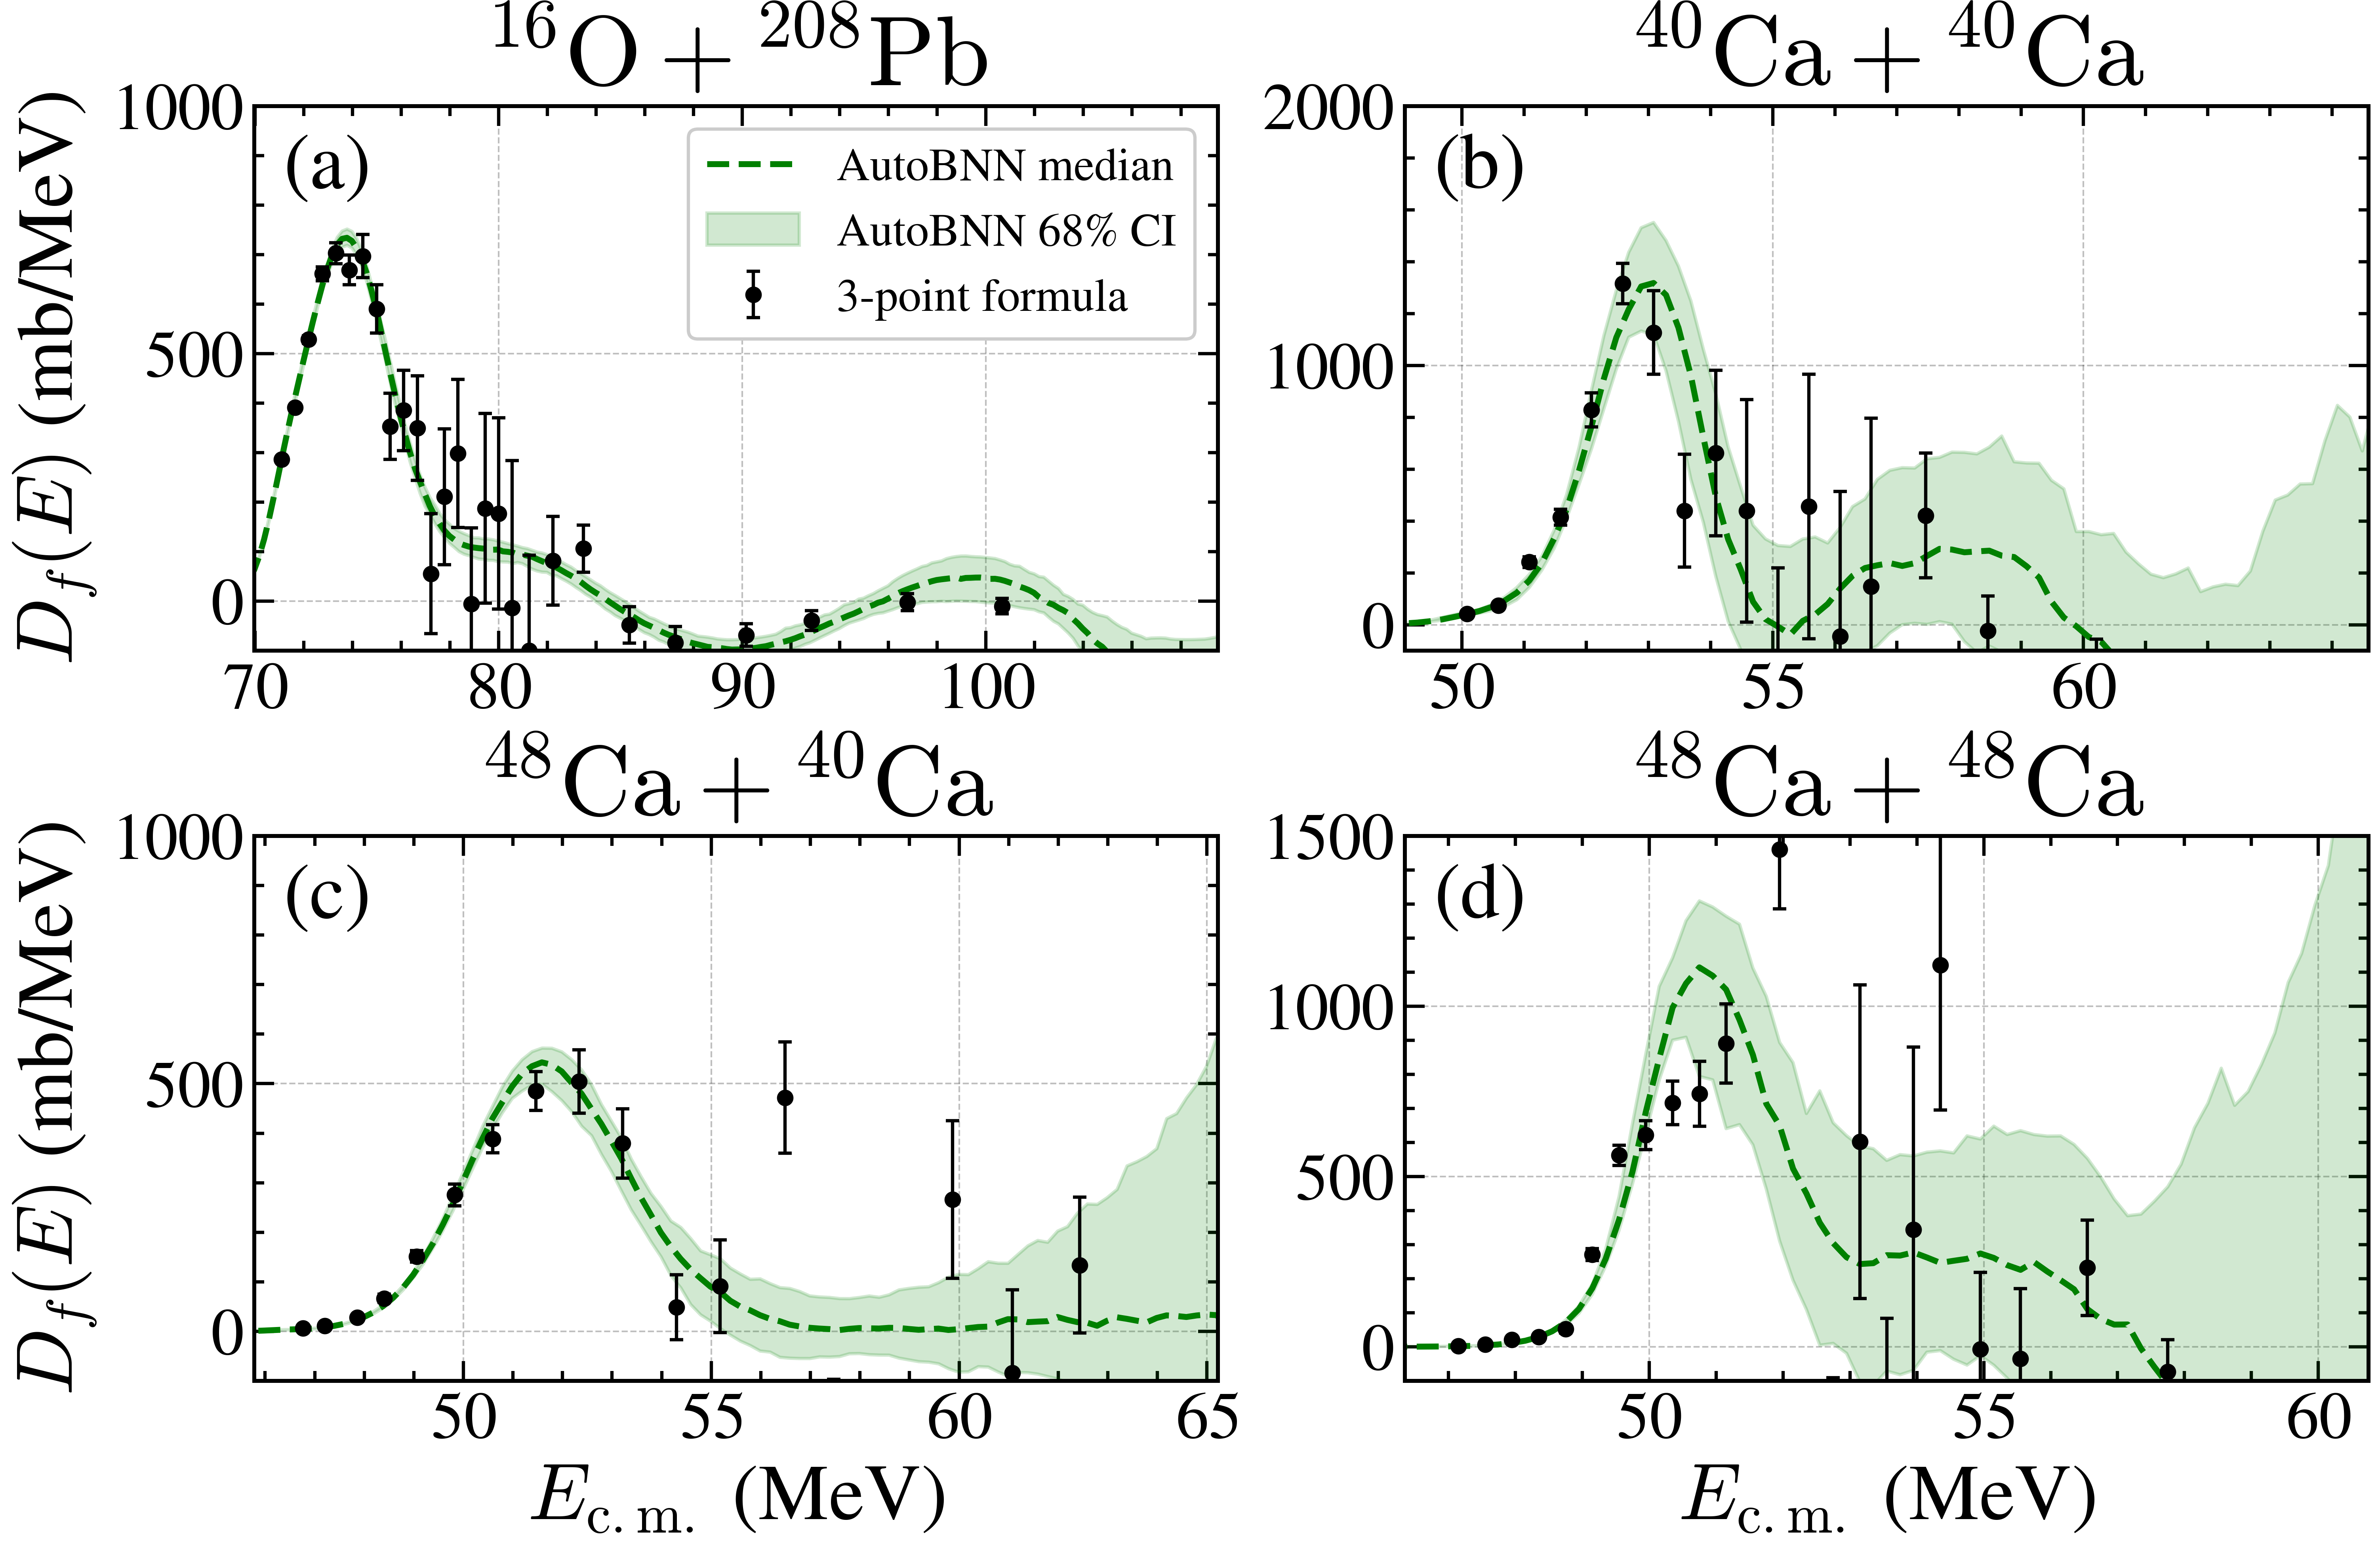

16O208PbMorton1999: using 00000_run08 (total_loss_mean=1965.18)
40Ca40CaMontagnoli2012: using 00001_run01 (total_loss_mean=2069.91)
48Ca40CaJiang2010: using 00002_run07 (total_loss_mean=2054.03)
48Ca48CaStefanini2009: using 00003_run00 (total_loss_mean=2052.22)


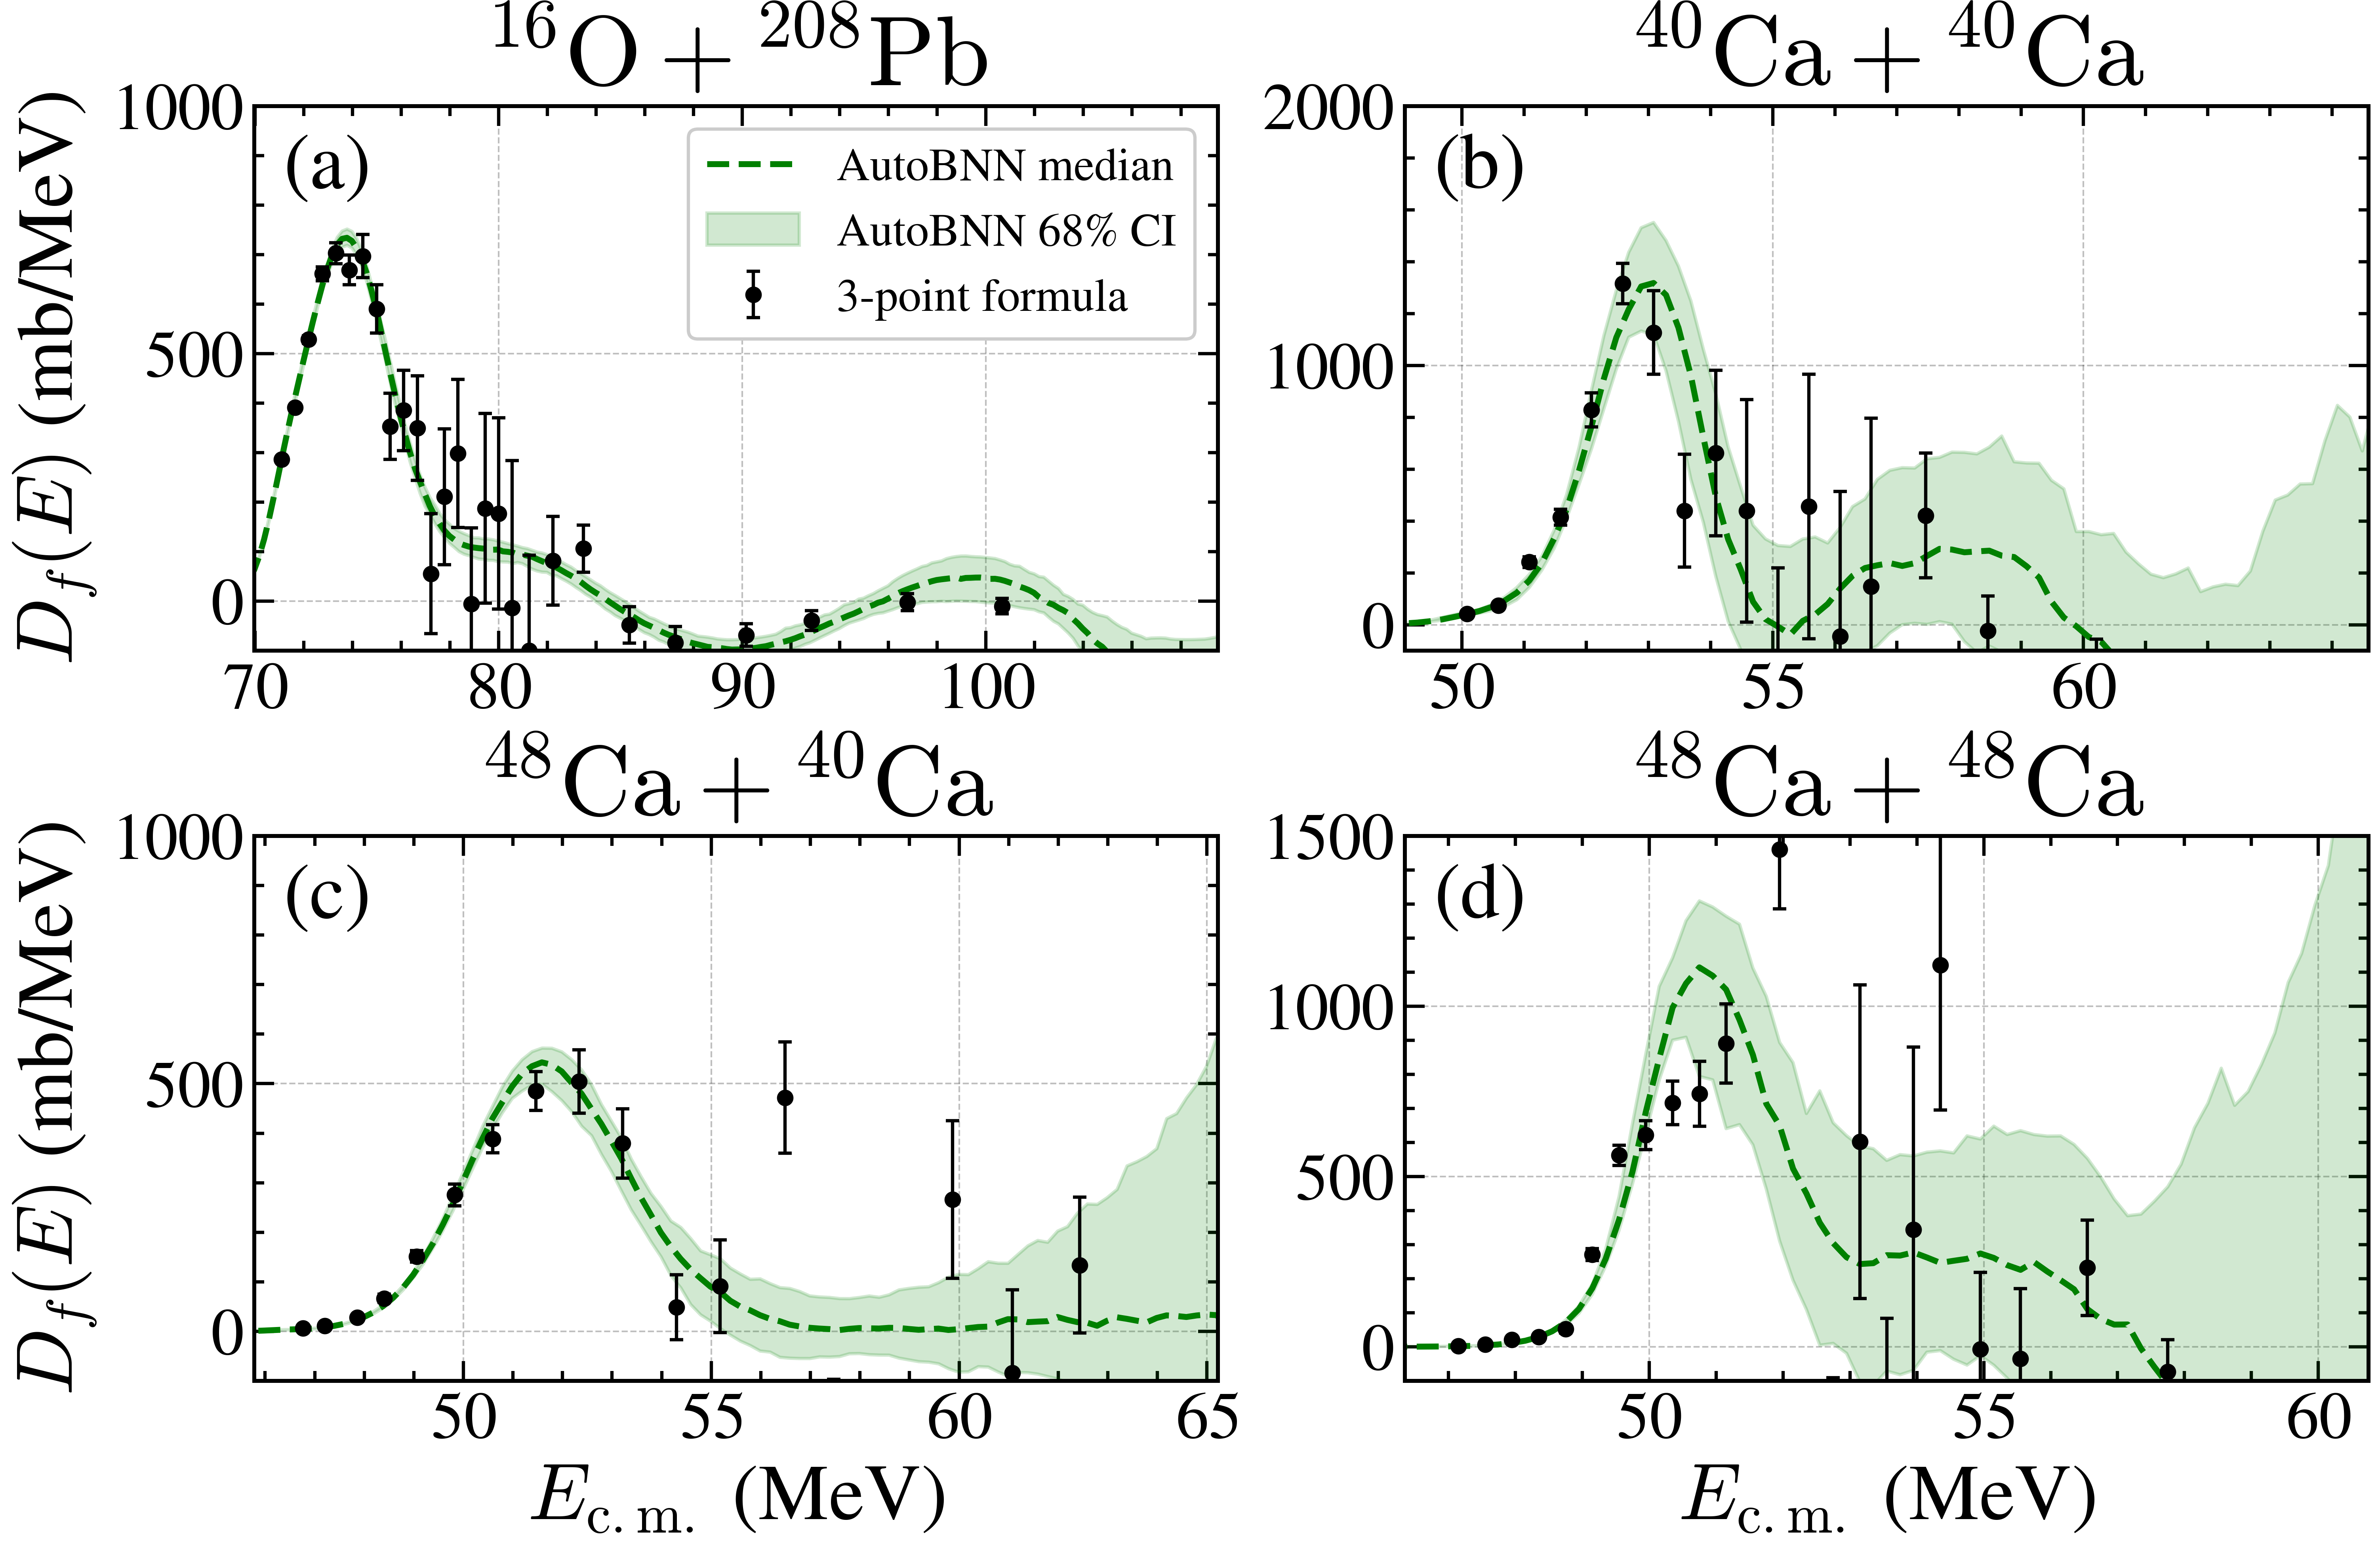

In [10]:
path_base = str(PROJECT_ROOT / "data" / "results" / "experiments8_d3_sweep")
save_dir = "../plots"

DE_STENCIL = 2
LOSS_ATTR = "total_loss_mean"
rows = []

titles = (
    "16O208PbMorton1999",
    "40Ca40CaMontagnoli2012",
    "48Ca40CaJiang2010",
    "48Ca48CaStefanini2009",
)

reaction_labels = [
    r"$^{16}\mathrm{O} + ^{208}\mathrm{Pb}$",
    r"$^{40}\mathrm{Ca} + ^{40}\mathrm{Ca}$",
    r"$^{48}\mathrm{Ca} + ^{40}\mathrm{Ca}$",
    r"$^{48}\mathrm{Ca} + ^{48}\mathrm{Ca}$",
]

ylims = [
    (-100, 1000),   # 16O208PbMorton1999
    (-100, 2000),   # 40Ca40CaMontagnoli2012
    (-100, 1000),   # 48Ca40CaJiang2010
    (-100, 1500),   # 48Ca48CaStefanini2009
]


def select_lowest_loss_group(h5_file, dataset_idx, loss_attr=LOSS_ATTR):
    """Return the experiment group with the lowest saved total loss."""
    group_prefix = f"{int(dataset_idx):05d}_run"
    candidates = []

    for group_name in sorted(h5_file.keys()):
        if not group_name.startswith(group_prefix):
            continue

        grp = h5_file[group_name]
        if loss_attr == "total_loss_mean":
            if "base_loss_mean" in grp.attrs and "d3_penalty_loss_mean" in grp.attrs:
                loss_value = float(grp.attrs["base_loss_mean"]) + float(grp.attrs["d3_penalty_loss_mean"])
            elif "base_loss_samples" in grp and "d3_penalty_loss_samples" in grp:
                loss_value = float(np.nanmean(grp["base_loss_samples"][:] + grp["d3_penalty_loss_samples"][:]))
            else:
                continue
        elif loss_attr in grp.attrs:
            loss_value = float(grp.attrs[loss_attr])
        elif "base_loss_samples" in grp:
            loss_value = float(np.nanmean(grp["base_loss_samples"][:]))
        else:
            continue

        if np.isfinite(loss_value):
            candidates.append((loss_value, group_name))

    if not candidates:
        return None, np.nan

    return min(candidates, key=lambda item: item[0])



fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=False, layout="constrained")
axes = axes.ravel()

legend_handles = None
legend_labels = None

for idx, (title, rxn_label, ax) in enumerate(zip(titles, reaction_labels, axes)):
    h5_path = os.path.join(
        path_base,
        f"experiments_{title}_bnn_soc_d3lam_1.h5_8x1000_lognormal_soc_d3lam_1"
    )

    with h5py.File(h5_path, "r") as f:
        loss_value, group_name = select_lowest_loss_group(f, idx)
        if group_name is None:
            print(f"No finite {LOSS_ATTR} found in {h5_path}")
            ax.set_visible(False)
            continue

        grp = f[group_name]
        print(f"{title}: using {group_name} ({LOSS_ATTR}={loss_value:.6g})")

        x = grp["x_pred"][:]
        E_data = grp["E_data"][:]
        Sigma_data = grp["Sigma_data"][:]
        Sigma_err = Sigma_err_arr[idx]
        D_samples = grp["d2_samples"][:]
        D_median = np.median(D_samples, axis=0)

    E_pts, D_pts, D_pts_err = paper_three_point_barrier(
        E_data, Sigma_data, Sigma_err, dE=DE_STENCIL
    )

    line, = ax.plot(
        x, D_median, "--g", linewidth=1.8, label="AutoBNN median"
    )

    bands = percentile_bands(D_samples, levels=(0.68,))
    D_lo = bands["lower_68"]
    D_hi = bands["upper_68"]

    band = ax.fill_between(
        x, D_lo, D_hi,
        color="green", alpha=0.18,
        label="AutoBNN 68% CI"
    )

    pts = ax.errorbar(
        E_pts,
        D_pts,
        yerr=D_pts_err,
        fmt="o",
        color="black",
        ms=4,
        lw=1,
        capsize=2,
        label="3-point formula"
    )

    ax.set_xlim(E_data.min(), E_data.max())
    ax.set_ylim(ylims[idx])
    ax.set_title(rxn_label)
    ax.grid(True, alpha=0.25)

    if idx in [2, 3]:
        ax.set_xlabel(r"$E_{\mathrm{c.m.}}$ (MeV)")
    if idx in [0, 2]:
        ax.set_ylabel(r"$D_f(E)$ (mb/MeV)")

    ax.text(
        0.03, 0.95, f"({chr(97 + idx)})",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=24
    )

    if legend_handles is None:
        legend_handles = [line, band, pts]
        legend_labels = ["AutoBNN median", "AutoBNN 68% CI", "3-point formula"]

axes[0].legend(
    legend_handles,
    legend_labels,
    loc="upper right",
    frameon=True,
)

out_png = os.path.join(save_dir, "ExperimentalFits_median.png")
fig.savefig(out_png, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)


# Replica using the barrier and uncertainty prescriptions in Eqs. (39) and
# (41) of Measuring Barriers to Fusion.
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=False, layout="constrained")
axes = axes.ravel()
legend_handles = None
legend_labels = None

for idx, (title, rxn_label, ax) in enumerate(zip(titles, reaction_labels, axes)):
    h5_path = os.path.join(
        path_base,
        f"experiments_{title}_bnn_soc_d3lam_1.h5_8x1000_lognormal_soc_d3lam_1"
    )

    with h5py.File(h5_path, "r") as f:
        loss_value, group_name = select_lowest_loss_group(f, idx)
        if group_name is None:
            print(f"No finite {LOSS_ATTR} found in {h5_path}")
            ax.set_visible(False)
            continue

        grp = f[group_name]
        print(f"{title}: using {group_name} ({LOSS_ATTR}={loss_value:.6g})")
        x = grp["x_pred"][:]
        E_data = grp["E_data"][:]
        Sigma_data = grp["Sigma_data"][:]
        Sigma_err = Sigma_err_arr[idx]
        D_samples = grp["d2_samples"][:]
        D_median = np.median(D_samples, axis=0)

    E_pts, D_pts, D_pts_err = paper_three_point_barrier(
        E_data, Sigma_data, Sigma_err, dE=DE_STENCIL
    )

    line, = ax.plot(x, D_median, "--g", linewidth=1.8, label="AutoBNN median")
    bands = percentile_bands(D_samples, levels=(0.68,))
    band = ax.fill_between(
        x, bands["lower_68"], bands["upper_68"],
        color="green", alpha=0.18, label="AutoBNN 68% CI"
    )
    pts = ax.errorbar(
        E_pts, D_pts, yerr=D_pts_err,
        fmt="o", color="black", ms=4, lw=1, capsize=2,
        label="3-point formula"
    )

    ax.set_xlim(E_data.min(), E_data.max())
    ax.set_ylim(ylims[idx])
    ax.set_title(rxn_label)
    ax.grid(True, alpha=0.25)
    if idx in [2, 3]:
        ax.set_xlabel(r"$E_{\mathrm{c.m.}}$ (MeV)")
    if idx in [0, 2]:
        ax.set_ylabel(r"$D_f(E)$ (mb/MeV)")
    ax.text(
        0.03, 0.95, f"({chr(97 + idx)})", transform=ax.transAxes,
        ha="left", va="top", fontsize=24
    )

    if legend_handles is None:
        legend_handles = [line, band, pts]
        legend_labels = ["AutoBNN median", "AutoBNN 68% CI", "3-point formula"]

axes[0].legend(legend_handles, legend_labels, loc="upper right", frameon=True)
out_png = os.path.join(save_dir, "ExperimentalFits_median_paper3point.png")
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### Demonstration of Failure

In [11]:
def plot_single_fit(gp_h5_path, bnn_h5_path, fit_index, dE=3, sigma_ylim=None,
                    barrier_ylim=None, center="mean", out_name="ExampleFail.png",
                    residual_inset_bounds=[0.52, 0.075, 0.43, 0.30]):
    """
    Plot a single fit from an HDF5 file with two vertically stacked panels:
      top    : sigma(E)
      bottom : barrier distribution D(E) with point-diff data
    Includes Wong true curves if the true parameters are stored in attrs.
    """
    with h5py.File(gp_h5_path, "r") as f:
        grp = f[str(int(fit_index))]

        # Load arrays
        x = grp["x_pred"][:]
        y_mean = grp["y_mean"][:]
        y_samples = grp["y_samples"][:]

        E_data = grp["E_data"][:]
        Sigma_data = grp["Sigma_data"][:]
        Sigma_err = grp["Sigma_err"][:]

        # True Wong parameters
        E0_true = float(grp.attrs["E0_true"])
        R0_true = float(grp.attrs["R0_true"])
        hw_true = float(grp.attrs["hw_true"])
        E0_fit = float(grp.attrs.get("E0_fit", np.nan))
        print(E_data)

    with h5py.File(bnn_h5_path, "r") as f:
        grp = f[str(int(fit_index // 10))]

        # Load arrays
        x_bnn = grp["x_pred"][:]
        y_mean_bnn = grp["y_mean"][:]
        y_samples_bnn = grp["y_samples"][:]

        E_data = grp["E_data"][:]
        print(E_data)

    if center not in {"mean", "median"}:
        raise ValueError("center must be 'mean' or 'median'")

    # GP barrier curves
    D_samples = barrier_from_sigma_samples(x, y_samples)
    y_center = y_mean if center == "mean" else np.nanmedian(y_samples, axis=0)
    D_center = (
        barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]
        if center == "mean" else np.nanmedian(D_samples, axis=0)
    )

    # AutoBNN barrier curves
    D_samples_bnn = barrier_from_sigma_samples(x_bnn, y_samples_bnn)
    y_center_bnn = y_mean_bnn if center == "mean" else np.nanmedian(y_samples_bnn, axis=0)
    D_center_bnn = (
        barrier_from_sigma_samples(x_bnn, y_mean_bnn.reshape(1, -1))[0]
        if center == "mean" else np.nanmedian(D_samples_bnn, axis=0)
    )

    # Wong true curves
    sigma_true = sigma(x, E0=E0_true, R0=R0_true, hbarw=hw_true)
    D_true = barrier_from_sigma_samples(x, sigma_true.reshape(1, -1))[0]

    # Credible bands: GP
    sbands = percentile_bands(y_samples, levels=(0.68,))
    s_lo = sbands["lower_68"]
    s_hi = sbands["upper_68"]

    dbands = percentile_bands(D_samples, levels=(0.68,))
    D_lo = dbands["lower_68"]
    D_hi = dbands["upper_68"]

    # Credible bands: AutoBNN
    sbands_bnn = percentile_bands(y_samples_bnn, levels=(0.68,))
    s_lo_bnn = sbands_bnn["lower_68"]
    s_hi_bnn = sbands_bnn["upper_68"]

    dbands_bnn = percentile_bands(D_samples_bnn, levels=(0.68,))
    D_lo_bnn = dbands_bnn["lower_68"]
    D_hi_bnn = dbands_bnn["upper_68"]

    # Three-point barrier points from experimental data
    E_pts, D_pts_plot, D_pts_err_plot = paper_three_point_barrier(
        E_data, Sigma_data, Sigma_err, dE=dE
    )
    point_label = "3-point formula"

    # Figure
    fig, (ax_sigma, ax_barrier) = plt.subplots(
        2, 1,
        figsize=(7, 10),
        sharex=True,
        gridspec_kw={"hspace": 0.08},
        layout="constrained",
    )

    c_gp   = "#3B5BA5"   # deep restrained blue
    c_bnn  = "#2A7F62"   # deep teal-green
    c_true = "#C44E52"   # muted brick red
    c_data = "#303030"   # charcoal
    c_diff = "#542788"   # dark purple

    # ---------------------------
    # sigma panel
    # ---------------------------

    ax_sigma.plot(
        x, sigma_true, "-",
        color=c_true, lw=3,
        label="Wong (ground truth)",
        zorder=2,
    )

    ax_sigma.plot(
        x, y_center,
        color=c_gp, ls="-.", lw=3,
        label=f"GP {center}",
        zorder=4,
    )

    ax_sigma.plot(
        x_bnn, y_center_bnn,
        color=c_bnn, ls="--", lw=3,
        label=f"AutoBNN {center}",
        zorder=3,
    )

    ax_sigma.fill_between(
        x, s_lo, s_hi,
        color=c_gp, alpha=0.2,
        label="GP 68% band",
    )

    ax_sigma.fill_between(
        x_bnn, s_lo_bnn, s_hi_bnn,
        color=c_bnn, alpha=0.2,
        label="AutoBNN 68% band",
    )

    ax_sigma.errorbar(
        E_data, Sigma_data, yerr=Sigma_err,
        fmt="o", color="black", mfc=c_data, mew=1.5,
        markersize=8, alpha=1.0, capsize=3,
        label="Simulated Exp. Measurements",
        lw=2, zorder=5,
    )

    # ---------------------------
    # residual inset
    # ---------------------------

    sigma_true_bnn = sigma(x_bnn, E0=E0_true, R0=R0_true, hbarw=hw_true)
    sigma_true_data = sigma(E_data, E0=E0_true, R0=R0_true, hbarw=hw_true)

    residual_gp = y_center - sigma_true
    residual_bnn = y_center_bnn - sigma_true_bnn
    residual_data = Sigma_data - sigma_true_data

    E_left, E_right = E_data.min(), E_data.max()
    gp_in_data = (x >= E_left) & (x <= E_right)
    bnn_in_data = (x_bnn >= E_left) & (x_bnn <= E_right)

    ax_resid = ax_sigma.inset_axes(residual_inset_bounds)
    ax_resid.set_facecolor("white")

    ax_resid.axhline(0.0, color="0.35", lw=1.0, zorder=1)

    ax_resid.plot(
        x[gp_in_data], residual_gp[gp_in_data],
        color=c_gp, ls="-.", lw=3.0,
        label="GP",
        zorder=2,
    )

    ax_resid.plot(
        x_bnn[bnn_in_data], residual_bnn[bnn_in_data],
        color=c_bnn, ls="--", lw=3.0,
        label="AutoBNN",
        zorder=2,
    )

    ax_resid.errorbar(
        E_data, residual_data, yerr=Sigma_err,
        fmt="o",
        color="black",
        mfc=c_data,
        mec="black",
        ms=5.5,
        elinewidth=1.2,
        capsize=2.5,
        markeredgewidth=0.6,
        label="Data",
        zorder=3,
    )

    residual_values = np.concatenate([
        residual_gp[gp_in_data],
        residual_bnn[bnn_in_data],
        residual_data - Sigma_err,
        residual_data + Sigma_err,
    ])
    residual_values = residual_values[np.isfinite(residual_values)]

    if residual_values.size:
        residual_abs = np.nanmax(np.abs(residual_values))
        residual_abs = max(residual_abs, 1.0)
        residual_pad = 0.10 * residual_abs
        ax_resid.set_ylim(-residual_abs - residual_pad, residual_abs + residual_pad)

    residual_xpad = 1.0
    ax_resid.set_xlim(E_left - residual_xpad, E_right + residual_xpad)

    # Cleaner inset labeling: no title, internal label instead
    ax_resid.set_ylabel("")
    ax_resid.text(
        0.04, 0.92,
        r"Residual",
        transform=ax_resid.transAxes,
        ha="left", va="top",
        fontsize=16,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.0),
    )

    # Use sparse major ticks only
    ax_resid.set_xticks([70, 80, 90])
    ax_resid.set_yticks([-10, 0, 10])

    ax_resid.minorticks_off()
    ax_resid.tick_params(
        axis="both",
        which="major",
        direction="in",
        top=True,
        right=True,
        labelsize=13,
        width=1.2,
        length=5,
        pad=2,
    )

    for spine in ax_resid.spines.values():
        spine.set_linewidth(1.2)

    ax_resid.grid(
        True,
        which="major",
        color="gray",
        alpha=0.22,
        lw=0.7,
        ls="--",
    )

    # ---------------------------
    # barrier panel
    # ---------------------------

    ax_barrier.fill_between(x, D_lo, D_hi, color=c_gp, alpha=0.2)
    ax_barrier.fill_between(x_bnn, D_lo_bnn, D_hi_bnn, color=c_bnn, alpha=0.2)

    ax_barrier.plot(x, D_true, "-", color=c_true, lw=3)
    ax_barrier.plot(x, D_center, color=c_gp, ls="-.", lw=3)
    ax_barrier.plot(x_bnn, D_center_bnn, color=c_bnn, ls="--", lw=3)

    diff_pts = ax_barrier.errorbar(
        E_pts, D_pts_plot, yerr=D_pts_err_plot,
        fmt="s",
        color=c_diff,
        mfc=c_diff,
        mec=c_diff,
        mew=1.5,
        ms=7,
        lw=2,
        capsize=3,
        label=point_label,
        zorder=5,
    )

    title = "Example Barrier Extraction"
    if np.isfinite(E0_fit):
        title += f" $E_0^{{\\rm fit}}={E0_fit:.2f}$, $E_0^{{\\rm true}}={E0_true:.2f}$"

    ax_sigma.set_ylabel(r"$\sigma(E)$ (mb)", labelpad=10)

    ax_sigma.text(
        0.95, 0.95, f"({chr(97)})",
        transform=ax_sigma.transAxes,
        ha="right", va="top",
        fontsize=24,
    )

    sigma_handles, sigma_labels = ax_sigma.get_legend_handles_labels()
    ax_sigma.legend(
        sigma_handles + [diff_pts],
        sigma_labels + [point_label],
        frameon=False,
        fontsize=16,
        loc="best",
    )

    if sigma_ylim is not None:
        ax_sigma.set_ylim(sigma_ylim)
    else:
        y_min = np.nanmin(np.concatenate([Sigma_data, s_lo, y_center, sigma_true]))
        y_max = np.nanmax(np.concatenate([Sigma_data, s_hi, y_center, sigma_true]))
        pad = 0.05 * (y_max - y_min + 1e-12)
        ax_sigma.set_ylim(y_min - pad, y_max + pad)

    sigma_tick_max = ax_sigma.get_ylim()[1]
    ax_sigma.set_yticks(np.arange(0.0, sigma_tick_max + 200.0, 200.0))

    ax_sigma.grid(True, color="gray", alpha=0.3)

    ax_barrier.set_xlabel(r"$E_{\mathrm{c.m.}}$ (MeV)")
    ax_barrier.set_ylabel(r"$D_f(E)$ (mb/MeV)", labelpad=10)

    # Keep stacked-panel y-labels aligned despite different tick-label widths.
    for ax in (ax_sigma, ax_barrier):
        ax.yaxis.set_label_coords(-0.12, 0.5)


    ax_barrier.text(
        0.95, 0.95, f"({chr(97 + 1)})",
        transform=ax_barrier.transAxes,
        ha="right", va="top",
        fontsize=24,
    )

    ax_barrier.set_xlim(E_data.min() - 0.5, E_data.max() + 0.5)
    ax_barrier.grid(True, color="gray", alpha=0.3)

    if barrier_ylim is not None:
        ax_barrier.set_ylim(barrier_ylim)
    else:
        y_min = np.nanmin(np.concatenate([D_lo, D_center, D_true, D_pts_plot]))
        y_max = np.nanmax(np.concatenate([D_hi, D_center, D_true, D_pts_plot]))
        pad = 0.08 * (y_max - y_min + 1e-12)
        ax_barrier.set_ylim(y_min - pad, y_max + pad)

    out_png = os.path.join(save_dir, out_name)

    fig.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

[64.56204276 65.65232803 67.14257966 68.27408555 69.14254432 69.7085344
 70.75811739 71.76521004 72.81484561 73.92492325 74.8285901  76.34197958
 77.30931061 77.9019115  79.09104427 80.30284794 80.88637786 82.02060873
 82.91621696 83.73972263 85.02269235 86.28078834 86.7513548  87.67153785
 88.61497428 90.02889604 91.40184984 92.68726842 93.16270588 93.91253662]
[64.56204276 65.65232803 67.14257966 68.27408555 69.14254432 69.7085344
 70.75811739 71.76521004 72.81484561 73.92492325 74.8285901  76.34197958
 77.30931061 77.9019115  79.09104427 80.30284794 80.88637786 82.02060873
 82.91621696 83.73972263 85.02269235 86.28078834 86.7513548  87.67153785
 88.61497428 90.02889604 91.40184984 92.68726842 93.16270588 93.91253662]


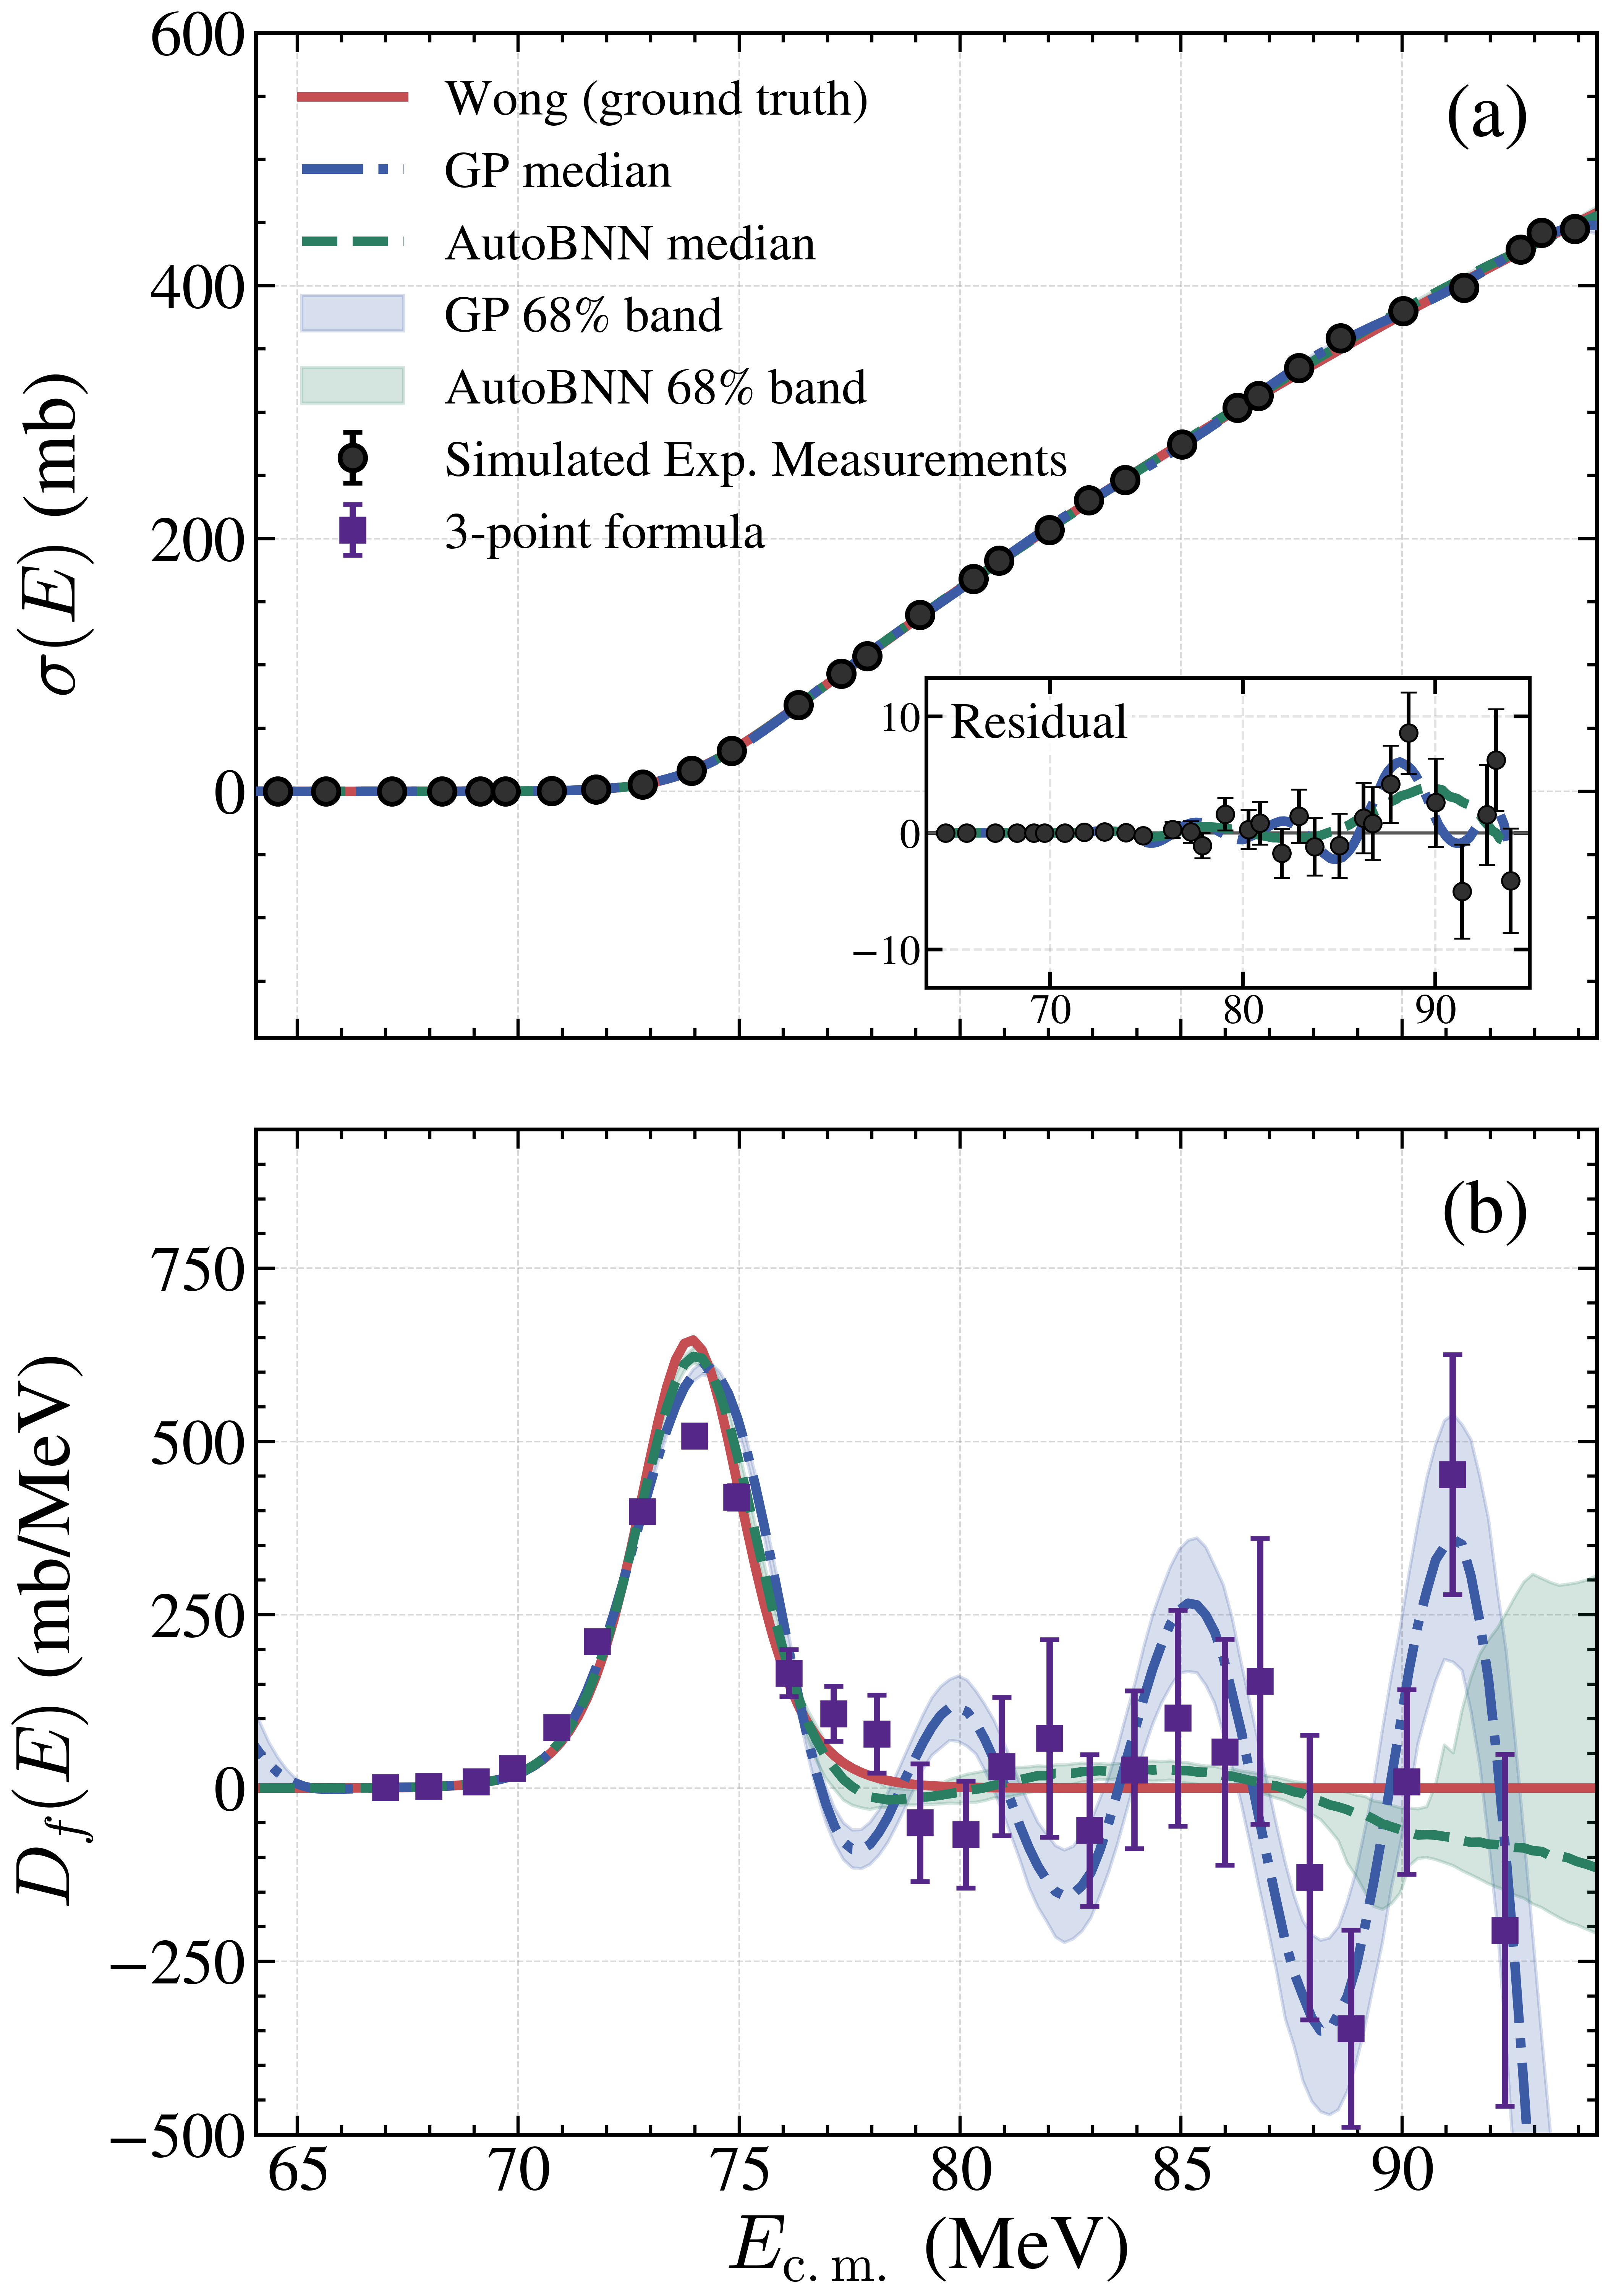

In [12]:
save_dir = "../plots"
DE_STENCIL = 2

# The repo copy of the GP file is slimmed to the plotted group so it can be
# committed to GitHub. To inspect or replot from the full original file, use:
# FULL_SCRATCH_GP_H5 = "/mnt/home/philipaa/scratch/barrier-paper-results/d3lambda1_rerun/gps/cv0.25_spacing1.0_gp_rbf.h5"
# and replace gp_h5_path below with FULL_SCRATCH_GP_H5.

plot_single_fit(
    gp_h5_path=str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "gps" / "cv0.25_spacing1.0_gp_rbf.h5"),
    bnn_h5_path=str(PROJECT_ROOT / "data" / "results" / "d3lambda1_rerun" / "bnns_with_df" / "cv0.25_spacing1.0_bnn_soc_d3lam1.h5"),
    fit_index=240, # 680, 240, 420, 430, 490
    dE=2,
    sigma_ylim=(-195, 600),
    barrier_ylim=(-500, 950),
    center="median",
    out_name="ExampleFail_median.png",
    residual_inset_bounds=[0.50, 0.05, 0.45, 0.308]
)